# 1. Import Libraries

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


# 2. Data Loading

In [17]:
train = pd.read_csv("../Dataset/fraudTrain.csv")
test = pd.read_csv("../Dataset/fraudTest.csv")

# Load the datasets

train = pd.read_csv("../Dataset/fraudTrain.csv")
test = pd.read_csv("../Dataset/fraudTest.csv")

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

Training Dataset Shape: (1296675, 23)
Testing Dataset Shape: (555719, 23)


# 3. Data Cleaning

In [18]:
# Display first 5 records
train.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [19]:
# Display dataset information
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [20]:
# Check dataset dimensions
print("Number of Rows:", train.shape[0])
print("Number of Columns:", train.shape[1])

Number of Rows: 1296675
Number of Columns: 23


In [21]:
# Display column names
print(train.columns.tolist())

['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']


In [22]:
# Generate statistical overview
train.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [14]:
print(train.isnull().sum())

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64


In [23]:
# Calculate total missing values
print("Total Missing Values:", train.isnull().sum().sum())

Total Missing Values: 0


In [15]:
print(train.duplicated().sum())

0


In [24]:
# Check data types of all columns
print(train.dtypes)

Unnamed: 0                 int64
trans_date_trans_time     object
cc_num                     int64
merchant                  object
category                  object
amt                      float64
first                     object
last                      object
gender                    object
street                    object
city                      object
state                     object
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                       object
dob                       object
trans_num                 object
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object


In [6]:
train.shape

(1296675, 23)

# 5. Pandas Data Analysis

In [25]:
# Count total transactions
total_transactions = len(train)
print("Total Transactions:", total_transactions)

Total Transactions: 1296675


In [26]:
# Calculate total transaction amount
total_amount = train['amt'].sum()
print("Total Transaction Amount:", round(total_amount, 2))

Total Transaction Amount: 91222428.9


In [27]:
# Filter fraudulent transactions
fraud_data = train[train['is_fraud'] == 1]
print("Total Fraud Transactions:", len(fraud_data))

Total Fraud Transactions: 7506


In [28]:
# Calculate fraud percentage
fraud_percentage = (len(fraud_data) / len(train)) * 100
print("Fraud Percentage:", round(fraud_percentage, 2), "%")

Fraud Percentage: 0.58 %


In [29]:
# Count legitimate transactions
legitimate_data = train[train['is_fraud'] == 0]
print("Legitimate Transactions:", len(legitimate_data))

Legitimate Transactions: 1289169


In [30]:
# Calculate average transaction amount
average_amount = train['amt'].mean()
print("Average Transaction Amount:", round(average_amount, 2))

Average Transaction Amount: 70.35


In [31]:
# Find highest transaction amount
highest_amount = train['amt'].max()
print("Highest Transaction Amount:", highest_amount)

Highest Transaction Amount: 28948.9


In [32]:
# Count transactions by category
category_counts = train['category'].value_counts()
print(category_counts)

category
gas_transport     131659
grocery_pos       123638
home              123115
shopping_pos      116672
kids_pets         113035
shopping_net       97543
entertainment      94014
food_dining        91461
personal_care      90758
health_fitness     85879
misc_pos           79655
misc_net           63287
grocery_net        45452
travel             40507
Name: count, dtype: int64


In [33]:
# Calculate total spending per customer
customer_spending = train.groupby('cc_num')['amt'].sum()
# Find top 10 customers
top_customers = customer_spending.nlargest(10)
print(top_customers)

cc_num
6011367958204270    296436.73
4908846471916297    290478.49
6011438889172900    284013.50
36722699017270      280008.05
6011893664860915    278325.97
6011109736646996    278139.27
3583635130604947    278042.99
2712209726293386    277085.65
4836998673805450    275930.63
372509258176510     275889.68
Name: amt, dtype: float64


In [34]:
# Calculate fraud count by category
fraud_by_category = fraud_data['category'].value_counts()
print(fraud_by_category)

category
grocery_pos       1743
shopping_net      1713
misc_net           915
shopping_pos       843
gas_transport      618
misc_pos           250
kids_pets          239
entertainment      233
personal_care      220
home               198
food_dining        151
grocery_net        134
health_fitness     133
travel             116
Name: count, dtype: int64


In [40]:
# Convert transaction time into datetime format
train['trans_date_trans_time'] = pd.to_datetime(
    train['trans_date_trans_time']
)


In [38]:
# Extract hour from transaction date and time
train['trans_date_trans_time'] = pd.to_datetime(
    train['trans_date_trans_time']
)
train['hour'] = train['trans_date_trans_time'].dt.hour

In [39]:
# Count transactions for each hour
hourly_data = train.groupby('hour').size()

In [44]:
print(train[['trans_date_trans_time', 'hour']].head())
print(hourly_data.head())

  trans_date_trans_time  hour
0   2019-01-01 00:00:18     0
1   2019-01-01 00:00:44     0
2   2019-01-01 00:00:51     0
3   2019-01-01 00:01:16     0
4   2019-01-01 00:03:06     0
hour
0    42502
1    42869
2    42656
3    42769
4    41863
dtype: int64


In [41]:
# Extract hour from transaction time
train['hour'] = train['trans_date_trans_time'].dt.hour

print("Hour column added successfully!")

Hour column added successfully!


# 6. Data Visualization

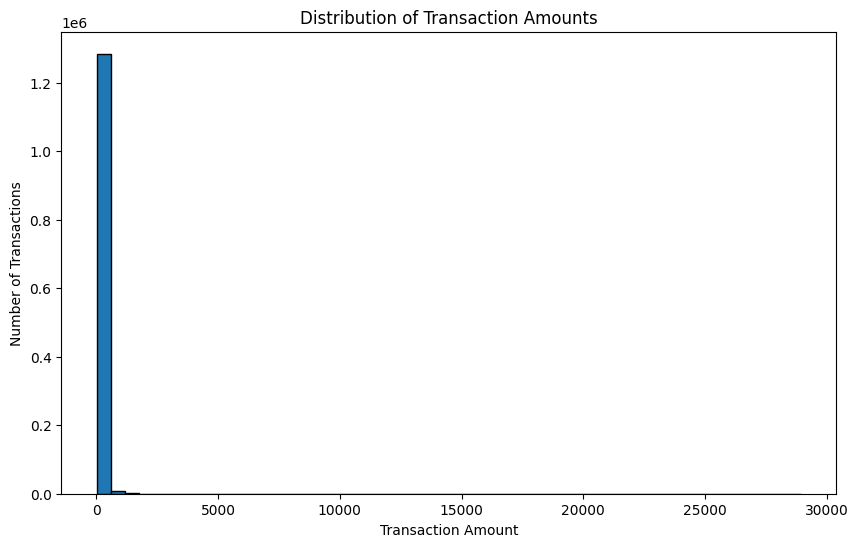

In [72]:
plt.figure(figsize=(10, 6))

plt.hist(train['amt'], bins=50, edgecolor='black')

plt.xlabel('Transaction Amount')
plt.ylabel('Number of Transactions')
plt.title('Distribution of Transaction Amounts')
plt.savefig("../Visualizations/01_transaction_histogram.png", bbox_inches='tight')
plt.show()

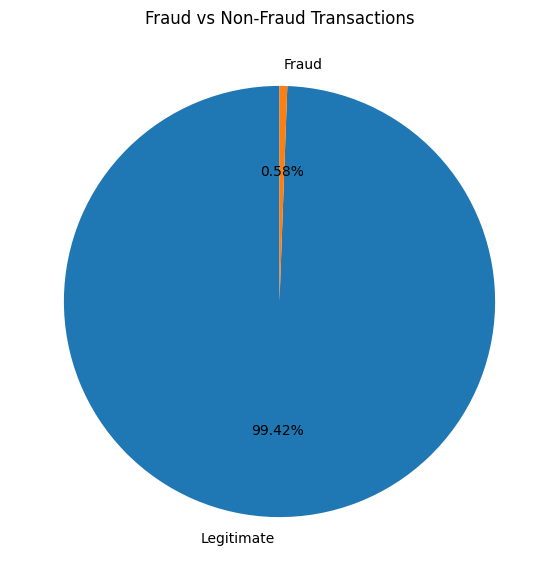

In [90]:
fraud_counts = train['is_fraud'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    fraud_counts,
    labels=['Legitimate', 'Fraud'],
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Fraud vs Non-Fraud Transactions')
plt.savefig("../Visualizations/02_fraud_pie_chart.png", bbox_inches='tight')
plt.show()

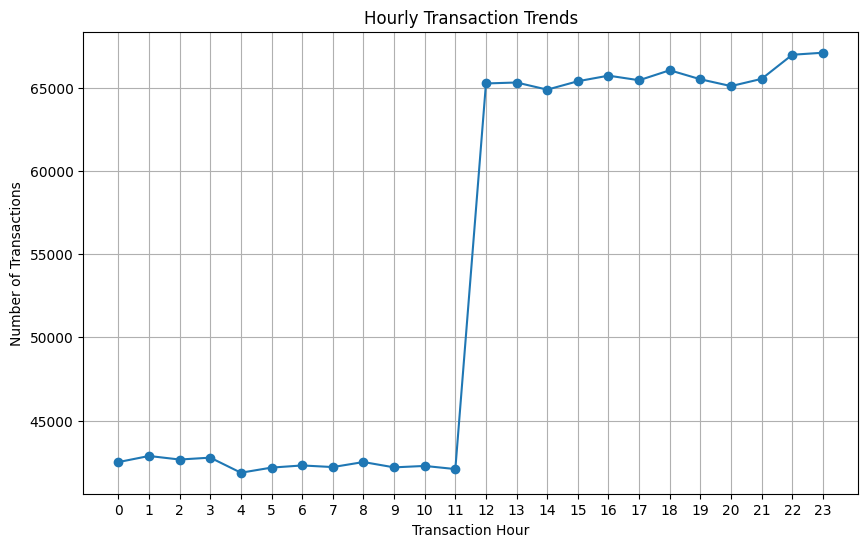

In [89]:
hourly_data = train.groupby('hour').size()

plt.figure(figsize=(10, 6))

plt.plot(hourly_data.index, hourly_data.values, marker='o')

plt.xlabel('Transaction Hour')
plt.ylabel('Number of Transactions')
plt.title('Hourly Transaction Trends')

plt.xticks(range(24))
plt.grid()
plt.savefig("../Visualizations/03_hourly_transaction_chart.png", bbox_inches='tight')
plt.show()

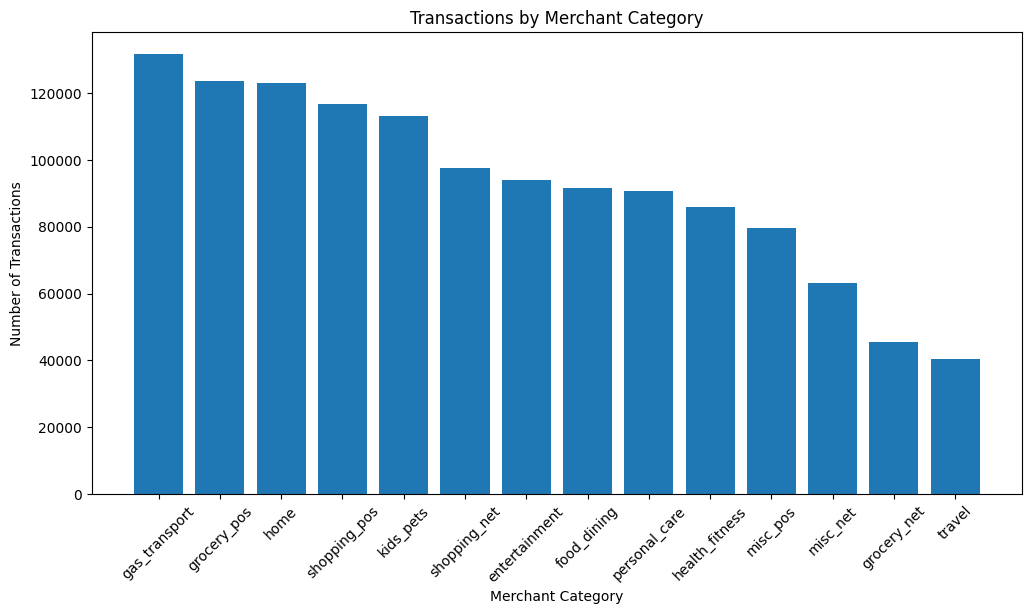

In [88]:
category_data = train['category'].value_counts()

plt.figure(figsize=(12, 6))

plt.bar(category_data.index, category_data.values)

plt.xlabel('Merchant Category')
plt.ylabel('Number of Transactions')
plt.title('Transactions by Merchant Category')

plt.xticks(rotation=45)
plt.savefig("../Visualizations/04_merchant_category_chart.png", bbox_inches='tight')
plt.show()

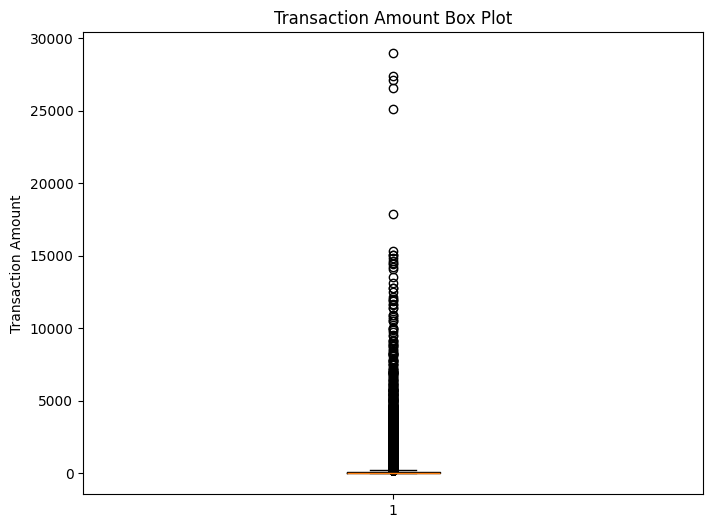

In [87]:
plt.figure(figsize=(8, 6))

plt.boxplot(train['amt'])

plt.ylabel('Transaction Amount')
plt.title('Transaction Amount Box Plot')
plt.savefig("../Visualizations/05_transaction_boxplot.png", bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

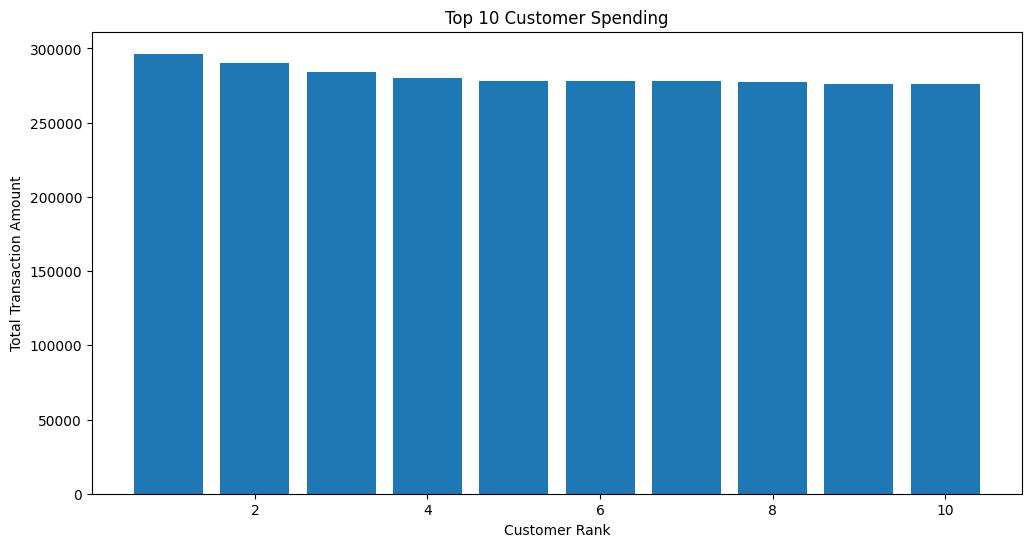

In [86]:
plt.savefig("../Visualizations/chart_name.png", bbox_inches='tight')
customer_spending = train.groupby('cc_num')['amt'].sum()

top_customers = customer_spending.nlargest(10)

plt.figure(figsize=(12, 6))

plt.bar(range(1, 11), top_customers.values)

plt.xlabel('Customer Rank')
plt.ylabel('Total Transaction Amount')
plt.title('Top 10 Customer Spending')
plt.savefig("../Visualizations/06_customer_spending_chart.png", bbox_inches='tight')
plt.show()

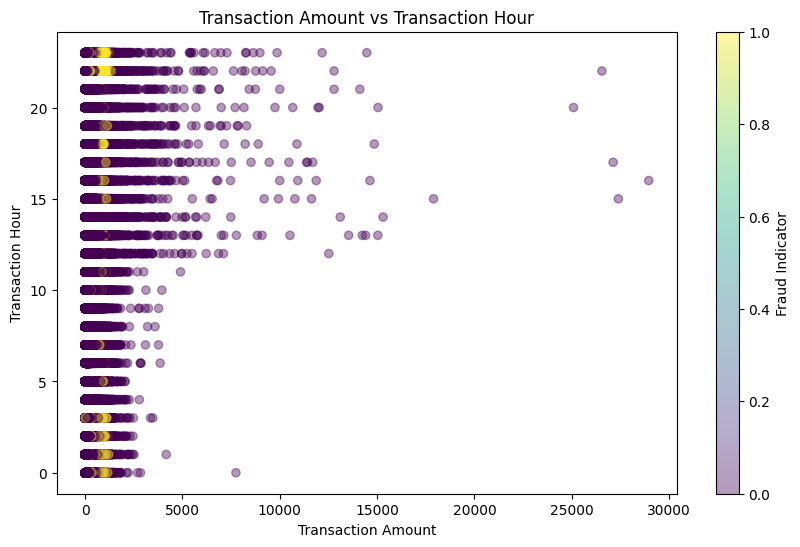

In [85]:
plt.figure(figsize=(10, 6))

plt.scatter(
    train['amt'],
    train['hour'],
    c=train['is_fraud'],
    alpha=0.4
)

plt.xlabel('Transaction Amount')
plt.ylabel('Transaction Hour')
plt.title('Transaction Amount vs Transaction Hour')

plt.colorbar(label='Fraud Indicator')
plt.savefig("../Visualizations/07_scatter_plot.png", bbox_inches='tight')
plt.show()

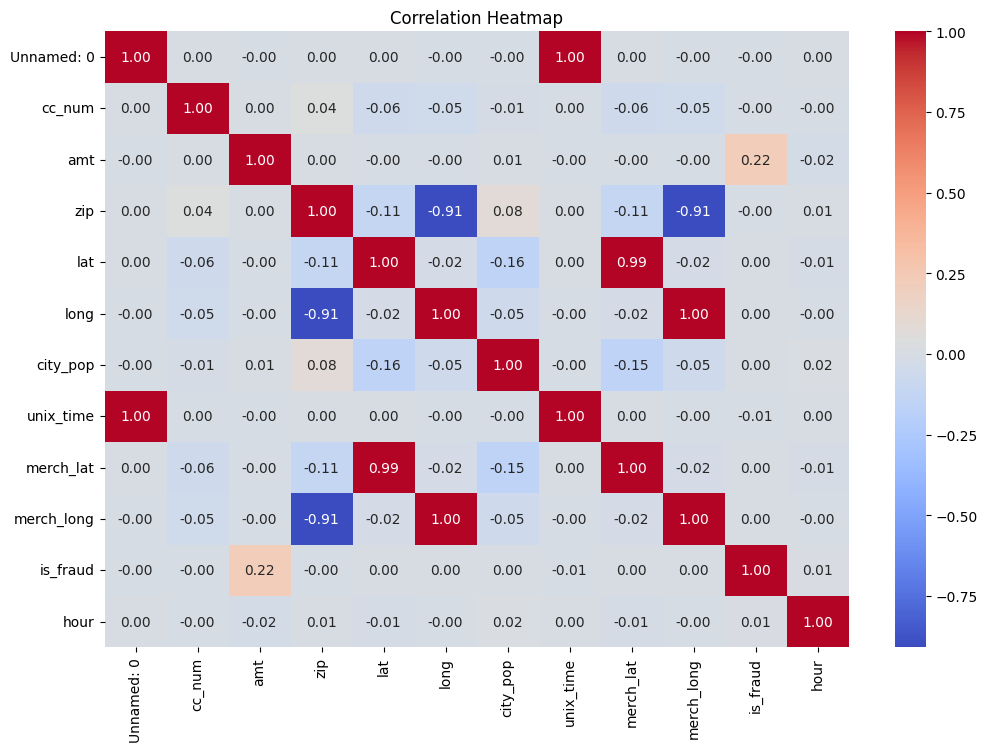

In [84]:
numeric_data = train.select_dtypes(include='number')

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.savefig("../Visualizations/08_correlation_heatmap.png", bbox_inches='tight')
plt.show()

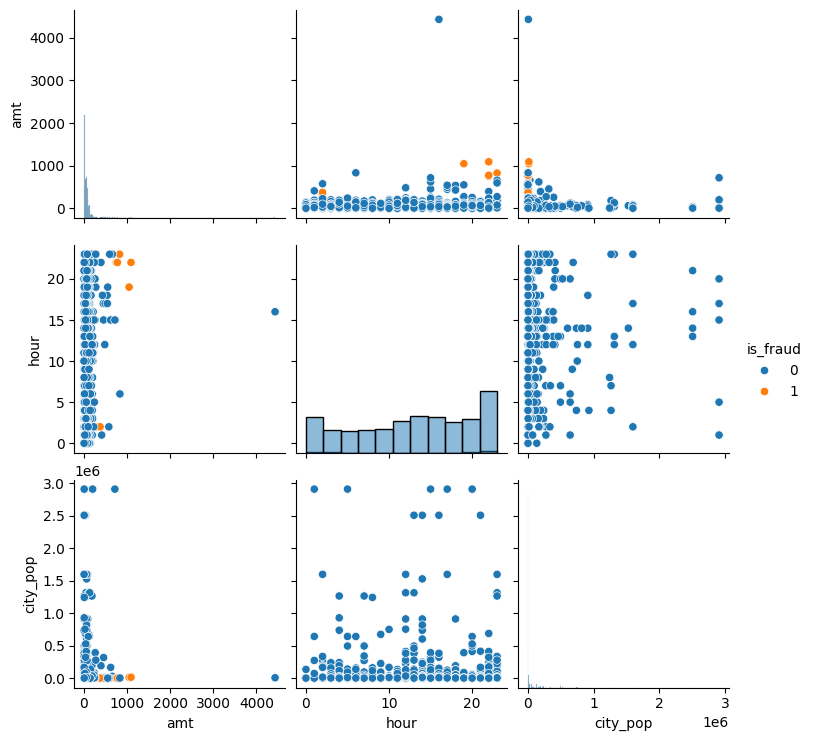

In [83]:
pair_data = train[
    ['amt', 'hour', 'city_pop', 'is_fraud']
].sample(n=1000, random_state=42)

sns.pairplot(
    pair_data,
    hue='is_fraud',
    diag_kind='hist'
)
plt.savefig("../Visualizations/09_pair_plot.png", bbox_inches='tight')
plt.show()

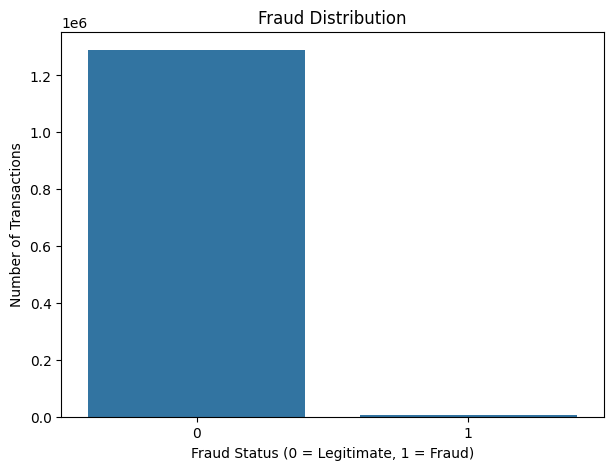

In [82]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x='is_fraud'
)

plt.xlabel('Fraud Status (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.title('Fraud Distribution')
plt.savefig("../Visualizations/10_fraud_count_plot.png", bbox_inches='tight')
plt.show()

# 7.1 Statistical Summary

In [53]:
# Generate Statistical Summary
summary = train.describe()

# Save summary as CSV
summary.to_csv("../Reports/statistical_summary.csv")
print("Statistical summary generated successfully!")

Statistical summary generated successfully!


# 7.2 Business Insights

In [54]:
# Calculate business insights
total_transactions = len(train)

fraud_transactions = train['is_fraud'].sum()

legitimate_transactions = total_transactions - fraud_transactions

fraud_percentage = (fraud_transactions / total_transactions) * 100

average_amount = train['amt'].mean()

highest_amount = train['amt'].max()

top_fraud_category = train[train['is_fraud'] == 1]['category'].value_counts().idxmax()

# Display business insights

print("BUSINESS INSIGHTS")
print("-------------------------")
print("Total Transactions:", total_transactions)
print("Fraud Transactions:", fraud_transactions)
print("Legitimate Transactions:", legitimate_transactions)
print("Fraud Percentage:", round(fraud_percentage, 2), "%")
print("Average Transaction Amount:", round(average_amount, 2))
print("Highest Transaction Amount:", highest_amount)
print("Category with Highest Fraud Count:", top_fraud_category)

BUSINESS INSIGHTS
-------------------------
Total Transactions: 1296675
Fraud Transactions: 7506
Legitimate Transactions: 1289169
Fraud Percentage: 0.58 %
Average Transaction Amount: 70.35
Highest Transaction Amount: 28948.9
Category with Highest Fraud Count: grocery_pos


# 7.3 Save Business Insights

In [55]:
# Save business insights in a text file

with open("../Reports/business_insights.txt", "w") as file:

    file.write("CREDIT CARD FRAUD ANALYSIS - BUSINESS INSIGHTS\n")
    file.write("----------------------------------------------\n")
    file.write(f"Total Transactions: {total_transactions}\n")
    file.write(f"Fraud Transactions: {fraud_transactions}\n")
    file.write(f"Legitimate Transactions: {legitimate_transactions}\n")
    file.write(f"Fraud Percentage: {round(fraud_percentage, 2)}%\n")
    file.write(f"Average Transaction Amount: {round(average_amount, 2)}\n")
    file.write(f"Highest Transaction Amount: {highest_amount}\n")
    file.write(f"Category with Highest Fraud Count: {top_fraud_category}\n")

print("Business insights saved successfully!")

Business insights saved successfully!


# 7.4 Generate PDF Report

In [56]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch

# Create PDF file
pdf = SimpleDocTemplate("../Reports/Credit_Card_Fraud_Report.pdf",
                        pagesize=A4)

styles = getSampleStyleSheet()

content = []

# Report title
content.append(Paragraph(
    "Credit Card Fraud Analysis Report",
    styles['Title']
))

content.append(Spacer(1, 0.3 * inch))

# Introduction
content.append(Paragraph(
    "This report presents an analysis of credit card transactions "
    "to understand fraud patterns and transaction behaviour.",
    styles['BodyText']
))

content.append(Spacer(1, 0.2 * inch))

# Business insights
content.append(Paragraph("Business Insights", styles['Heading2']))

insights = [
    f"Total Transactions: {total_transactions}",
    f"Fraud Transactions: {fraud_transactions}",
    f"Legitimate Transactions: {legitimate_transactions}",
    f"Fraud Percentage: {round(fraud_percentage, 2)}%",
    f"Average Transaction Amount: {round(average_amount, 2)}",
    f"Highest Transaction Amount: {highest_amount}",
    f"Category with Highest Fraud Count: {top_fraud_category}"
]

for insight in insights:
    content.append(Paragraph(insight, styles['BodyText']))
    content.append(Spacer(1, 0.1 * inch))

# Generate PDF
pdf.build(content)

print("PDF report generated successfully!")

PDF report generated successfully!


In [57]:
# Save the cleaned training dataset

train.to_csv(
    "../Reports/cleaned_fraud_dataset.csv",
    index=False
)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [91]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import inch
import os

# PDF file location
pdf_path = "../Reports/Credit_Card_Fraud_Report.pdf"

# All 10 saved chart filenames
chart_files = [
    "01_transaction_histogram.png",
    "02_fraud_pie_chart.png",
    "03_hourly_transaction_chart.png",
    "04_merchant_category_chart.png",
    "05_transaction_boxplot.png",
    "06_customer_spending_chart.png",
    "07_scatter_plot.png",
    "08_correlation_heatmap.png",
    "09_pair_plot.png",
    "10_fraud_count_plot.png"
]

# Check whether all chart images exist
missing_files = [
    chart for chart in chart_files
    if not os.path.exists("../Visualizations/" + chart)
]

if missing_files:
    print("These chart images are missing:")
    for chart in missing_files:
        print(chart)

else:
    # Create PDF document
    pdf = SimpleDocTemplate(
        pdf_path,
        pagesize=A4,
        rightMargin=45,
        leftMargin=45,
        topMargin=45,
        bottomMargin=45
    )

    styles = getSampleStyleSheet()
    content = []

    # 1. Project Introduction
    content.append(Paragraph(
        "Credit Card Fraud Analysis Report",
        styles['Title']
    ))
    content.append(Spacer(1, 20))

    content.append(Paragraph(
        "This project analyzes credit card transactions to understand "
        "fraud patterns, transaction behaviour, customer spending "
        "and merchant category trends.",
        styles['BodyText']
    ))
    content.append(Spacer(1, 25))

    # 2. Business Insights
    content.append(Paragraph(
        "Business Insights", styles['Heading1']
    ))
    content.append(Spacer(1, 12))

    insights = [
        "Total Transactions: 1,296,675",
        "Fraud Transactions: 7,506",
        "Legitimate Transactions: 1,289,169",
        "Fraud Percentage: 0.58%",
        "Average Transaction Amount: 70.35",
        "Highest Transaction Amount: 28,948.90",
        "Category with Highest Fraud Count: grocery_pos"
    ]

    for insight in insights:
        content.append(Paragraph(insight, styles['BodyText']))
        content.append(Spacer(1, 8))

    content.append(PageBreak())

    # 3. Statistical Summary
    content.append(Paragraph(
        "Statistical Summary", styles['Heading1']
    ))
    content.append(Spacer(1, 15))

    statistics = [
        "Total Records: 1,296,675",
        "Average Transaction Amount: 70.35",
        "Median Transaction Amount: 47.52",
        "Minimum Transaction Amount: 1.00",
        "Maximum Transaction Amount: 28,948.90",
        "Standard Deviation of Amount: 160.32",
        "Average Fraud Indicator: 0.005789"
    ]

    for item in statistics:
        content.append(Paragraph(item, styles['BodyText']))
        content.append(Spacer(1, 8))

    content.append(PageBreak())

    # 4. Add all 10 existing charts
    content.append(Paragraph(
        "Data Visualizations", styles['Heading1']
    ))
    content.append(Spacer(1, 15))

    for i, chart in enumerate(chart_files):

        chart_path = "../Visualizations/" + chart

        chart_title = chart.replace(".png", "")
        chart_title = chart_title[3:].replace("_", " ").title()

        content.append(Paragraph(
            f"{i+1}. {chart_title}",
            styles['Heading2']
        ))
        content.append(Spacer(1, 8))

        content.append(Image(
            chart_path,
            width=6*inch,
            height=3.5*inch,
            kind='proportional'
        ))

        content.append(Spacer(1, 15))

        if (i + 1) % 2 == 0 and i != len(chart_files) - 1:
            content.append(PageBreak())

    # 5. Final Recommendations
    content.append(PageBreak())

    content.append(Paragraph(
        "Final Recommendations", styles['Heading1']
    ))
    content.append(Spacer(1, 15))

    recommendations = [
        "Monitor transaction activity during hours with higher "
        "fraud counts.",

        "Pay closer attention to merchant categories with higher "
        "fraud rates.",

        "Investigate unusual transaction amounts and spending patterns.",

        "Use additional verification for transactions identified "
        "as suspicious.",

        "Continue monitoring fraud trends to support better "
        "transaction security."
    ]

    for recommendation in recommendations:
        content.append(Paragraph(
            "• " + recommendation,
            styles['BodyText']
        ))
        content.append(Spacer(1, 12))

    # Generate complete PDF
    pdf.build(content)

    print("Complete PDF report generated successfully!")

Complete PDF report generated successfully!
